<a href="https://colab.research.google.com/github/Lupo6789/tesi_scacchi/blob/main/04_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

NOTEBOOK 04: BENCHMARK MODELLI (LogReg vs Random Forest vs LightGBM)

Avvio addestramento ciclico.
Elaborazione Soglia N=10...
[LightGBM] [Info] Number of positive: 7367, number of negative: 6740
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001205 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 724
[LightGBM] [Info] Number of data points in the train set: 14107, number of used features: 12
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.522223 -> initscore=0.088951
[LightGBM] [Info] Start training from score 0.088951
Elaborazione Soglia N=20...
[LightGBM] [Info] Number of positive: 6895, number of negative: 6384
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.037622 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true

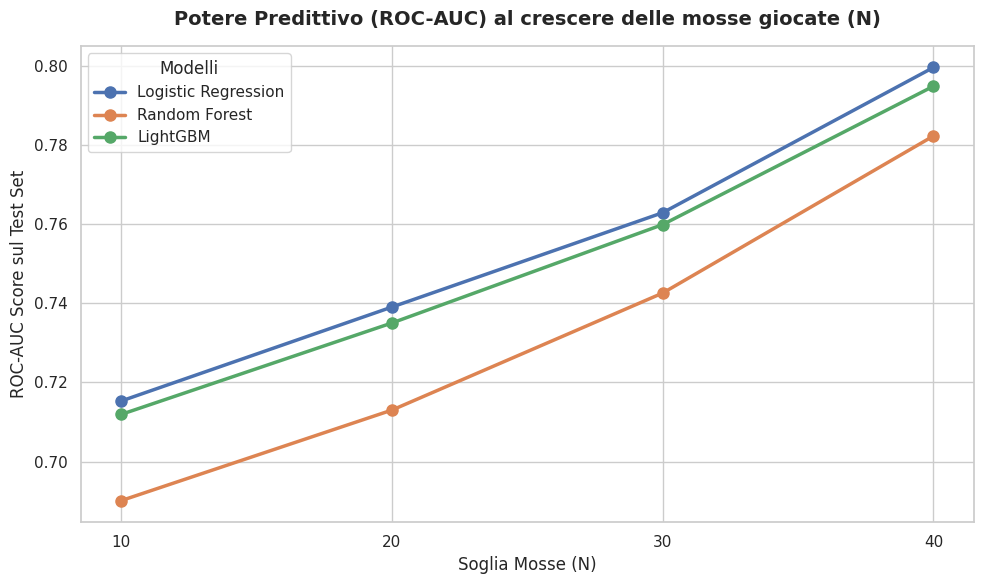

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import warnings

# Disabilita warning per mantenere l'output pulito
warnings.filterwarnings('ignore')

print("NOTEBOOK 04: BENCHMARK MODELLI (LogReg vs Random Forest vs LightGBM)\n")

soglie = [10, 20, 30, 40]
risultati_auc = {'N': soglie, 'Logistic Regression': [], 'Random Forest': [], 'LightGBM': []}

# 1. Definizione dei Modelli Base
modelli = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(random_state=42, max_iter=1000))
    ]),
    # Impostiamo n_jobs=-1 per usare tutti i core del processore e velocizzare
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(random_state=42, n_jobs=-1)
}

colonne_da_escludere = ['winner', 'id', 'white_id', 'black_id']

print("Avvio addestramento ciclico.")

# 2. Ciclo di addestramento su tutte le soglie N
for N in soglie:
    print(f"Elaborazione Soglia N={N}...")

    # Caricamento file per la soglia corrente
    df_train = pd.read_csv(f'train_features_N{N}.csv').dropna()
    df_test = pd.read_csv(f'test_features_N{N}.csv').dropna()

    y_train = df_train['winner']
    y_test = df_test['winner']

    # Pulizia delle colonne non predittive
    X_train = df_train.drop(columns=[col for col in colonne_da_escludere if col in df_train.columns])
    X_test = df_test.drop(columns=[col for col in colonne_da_escludere if col in df_test.columns])

    # Addestramento e Valutazione
    for nome_modello, modello in modelli.items():
        # Fit sul Train Set
        modello.fit(X_train, y_train)

        # Previsione probabilità sul Test Set e calcolo ROC-AUC
        y_prob = modello.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, y_prob)

        # Salvataggio risultato
        risultati_auc[nome_modello].append(auc)

print("\n RISULTATI ROC-AUC FINALI")
df_risultati = pd.DataFrame(risultati_auc)
print(df_risultati.to_string(index=False))

# 3. Creazione del Grafico (Plot ROC-AUC)
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Traccia una linea per ogni modello
for modello in modelli.keys():
    plt.plot(df_risultati['N'], df_risultati[modello], marker='o', linewidth=2.5, markersize=8, label=modello)

# Formattazione estetica del grafico
plt.title("Potere Predittivo (ROC-AUC) al crescere delle mosse giocate (N)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Soglia Mosse (N)", fontsize=12)
plt.ylabel("ROC-AUC Score sul Test Set", fontsize=12)
plt.xticks(soglie)
plt.legend(title="Modelli", fontsize=11, title_fontsize=12)
plt.tight_layout()

# Mostra il grafico
plt.show()

L'analisi visiva e numerica delle metriche ROC-AUC al crescere delle mosse giocate (N) rivela tre dinamiche fondamentali per lo sviluppo della tesi:

Si osserva un marcato e costante incremento del potere predittivo per tutti gli algoritmi testati. Passando dalla fase di apertura (N=10) al mediogioco inoltrato (N=40), l'AUC generale cresce da circa 0.71 a ridosso dello 0.80. Questo andamento testimonia il successo della fase di feature engineering: l'estrazione delle metriche posizionali (vantaggio materiale, mobilità, sicurezza) apporta un massiccio valore informativo man mano che le posizioni sulla scacchiera si sbilanciano.

Contro le aspettative teoriche, la Regressione Logistica sovraperforma i modelli ad albero (LightGBM e Random Forest) per tutta la durata della partita, seppur con margini ristretti. Questo fenomeno si spiega con la natura prevalentemente lineare, additiva e diretta del vantaggio materiale negli scacchi: un semplice modello lineare si rivela un "benchmark"  formidabile e difficile da superare a causa della natura matemaitica del vantaggio di materiale e di elo

C'è una chiara necessità di Ottimizzazione degli Iperparametri poichè
Il ritardo prestazionale dei modelli non-lineari  è indicativo dell'uso dei parametri di default.